## Rationale
### is LASV gp2 347-414 reactivity associated with neutralization phenotype? 

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Reproducibility / display
pd.set_option("display.max_columns", 100)
pd.set_option("display.precision", 4)
RNG = np.random.default_rng(20261021)

DATA_DIR = Path(".")
if not (DATA_DIR / "reactive_lasv_gp_347_414.csv").exists():
    DATA_DIR = Path("/mnt/data")

REACTIVE_FILE = DATA_DIR / "reactive_lasv_gp_347_414.csv"
MAIN_FILE = DATA_DIR / "LASV_ELISA_Neut_and_PhIP_Seq_result_corrected_w_month_year_filtered_first_tp.csv"

FIG_DIR = DATA_DIR / "paper_figures"
TABLE_DIR = DATA_DIR / "paper_tables"
FIG_DIR.mkdir(exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)

# Publication-oriented defaults. Adjust font/size to journal requirements.
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [3]:
reactive = pd.read_csv(REACTIVE_FILE)
main = pd.read_csv(MAIN_FILE)

# Remove accidental whitespace from column names (source contains "Neut_Result ").
reactive.columns = reactive.columns.str.strip()
main.columns = main.columns.str.strip()

# Basic ID hygiene
reactive["individual"] = reactive["individual"].astype(str).str.strip()
main["individual"] = main["individual"].astype(str).str.strip()

print("Reactive file:", reactive.shape)
print("Main file:", main.shape)
print("Reactive duplicate IDs:", reactive["individual"].duplicated().sum())
print("Main duplicate IDs:", main["individual"].duplicated().sum())
print("Neut_Result levels:", sorted(main["Neut_Result"].dropna().unique()))

Reactive file: (104, 3)
Main file: (397, 22)
Reactive duplicate IDs: 0
Main duplicate IDs: 0
Neut_Result levels: ['Moderate', 'Non-Neutralizing', 'Strong', 'Weak']


In [14]:
"""rationale here is to build a new dataframe which is built off the metadata table where each first tip individual has neut result and elisa serostatus
a 'Neutralizing' column is added to indicate if someone is neutralizing based on Weak, Moderate, Strong results, 
in addition to a 'Strong neutralizer' column, in case someone is strongly neutralizing.
If no Neut result available, it sets the result in 'Neutralizing' and 'Strong neutralizer' columns to nan, instead of False
"""

reactive_ids = set(reactive["individual"])
main_ids = set(main["individual"])
matched = reactive_ids & main_ids

print(f"Reactive IDs matched: {len(matched)}/{len(reactive_ids)}")
print("Reactive IDs absent from main dataset:", sorted(reactive_ids - main_ids))

# Analysis dataframe: one row per individual in the supplied first-timepoint dataset.
df = main.copy()
df["GP2_reactive"] = df["individual"].isin(reactive_ids)

def classify_group(x):
    if x.startswith("C-"):
        return "Household contact"
    if x.startswith("S-"):
        return "Survivor"
    return "Other"

df["Group"] = df["individual"].map(classify_group)
df["Neutralizing"] = df["Neut_Result"].isin(["Weak", "Moderate", "Strong"])
df["Strong_neutralizer"] = df["Neut_Result"].eq("Strong")

# Missing Neut_Result should remain missing for binary endpoints, not be coded False.
df.loc[df["Neut_Result"].isna(), ["Neutralizing", "Strong_neutralizer"]] = np.nan

df[["individual", "Group", "GP2_reactive", "Neut_Percent", "Neut_Result"]].head()

Reactive IDs matched: 104/104
Reactive IDs absent from main dataset: []


,individual,Group,GP2_reactive,Neut_Percent,Neut_Result
0,C-109-1_5_B3,Household contact,False,0.0000,Non-Neutralizing
1,C-109-2_5_B5,Household contact,False,3.5900,Non-Neutralizing
2,C-109-3_4_E7,Household contact,True,83.7719,Strong
3,C-110-1_2_A5,Household contact,False,68.9621,Moderate
4,C-110-2_3_F8,Household contact,False,49.0837,Non-Neutralizing


In [15]:
cohort_counts = (
    df.groupby(["Group", "GP2_reactive"], dropna=False) #want to keep rows where any grouping column might be NaN. should match total N
      .agg(n=("individual", "size"), n_neut_result=("Neut_Result", "count"))
      .reset_index()
)
cohort_counts["GP2_status"] = cohort_counts["GP2_reactive"].map({True:"GP-reactive", False:"GP-nonreactive"})
display(cohort_counts[["Group", "GP2_status", "n", "n_neut_result"]])
cohort_counts.to_csv(TABLE_DIR / "cohort_counts.csv", index=False)

,Group,GP2_status,n,n_neut_result
0,Household contact,GP-nonreactive,222,221
1,Household contact,GP-reactive,55,54
2,Survivor,GP-nonreactive,71,70
3,Survivor,GP-reactive,49,49


In [16]:
missing_neut = df.loc[df['Neut_Result'].isna(), ['individual', 'Group', 'GP2_reactive']]
display(missing_neut)

,individual,Group,GP2_reactive
14,C-114-1_7_B2,Household contact,True
96,C-183-2_3_A8,Household contact,False
323,S-168_SA2_B3,Survivor,False


### goal is to find an association between Neut Percent and GP2 region 347-414 reactivity

AttributeError: 'DataFrame' object has no attribute 'GP_reactive'

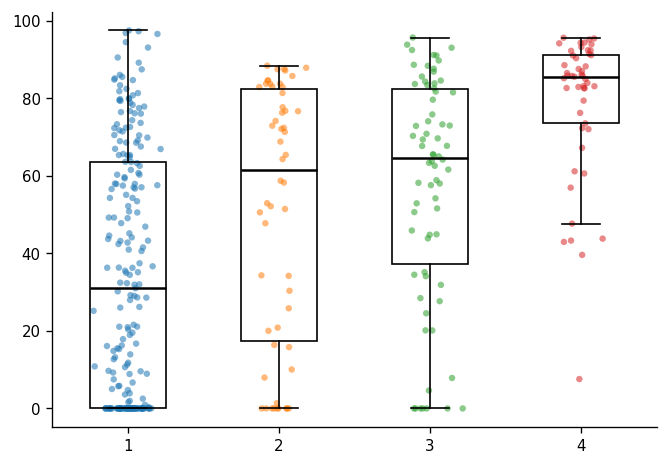

In [ ]:
groups = [
    ("Household contact", False, "Contact\nGP2-nonreactive"),
    ("Household contact", True,  "Contact\nGP2-reactive"),
    ("Survivor", False, "Survivor\nGP2-nonreactive"),
    ("Survivor", True,  "Survivor\nGP2-reactive"),
]

vals = []
labels = []

for group, gp, label in groups:
    v = df[
        (df.Group == group) &
        (df.GP2_reactive == gp)
    ]["Neut_Percent"].dropna().to_numpy() #need to drop nan

    vals.append(v)
    labels.append(f"{label}\n(n={len(v)})")


fig, ax = plt.subplots(figsize=(6.5, 4.5))

bp = ax.boxplot(
    vals, #boxplot accepts a list (or any sequence) of arrays and draws one box per array
    positions=np.arange(1, 5),
    widths=.5,
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "black", "linewidth": 1.5},
    boxprops={"facecolor": "none", "edgecolor": "black"}
)

# Individual observations
for group_number, values in enumerate(vals, 1): #i is the group unmber which sets the x position, v is the group's value which ets the y position
    jitter = RNG.normal(0, .07, len(v))

    #set box position, we have 4 different boxes for contact - non neut, contact - neut, survivor - non neut, survivor - neut
    x = np.full(len(values), group_number) + jitter #if values=[10, 25, 10], and group_num = 1, yields [1 1 1]. jitter adds small left/right shifts
    
    y = values

    ax.scatter(
        x, y,
        s=15,
        alpha=.55,
        edgecolors="none"
    )


# Statistics

pvals = {}

for group in ["Household contact", "Survivor"]:

    reactive = df[
        (df.Group == group) &
        df.GP_reactive
    ]["Neut_Percent"].dropna()

    nonreactive = df[
        (df.Group == group) &
        ~df.GP_reactive
    ]["Neut_Percent"].dropna()

    u, p = stats.mannwhitneyu(
        reactive,
        nonreactive,
        alternative="two-sided"
    )

    pvals[group] = p

    print(
        f"{group}: "
        f"reactive median={reactive.median():.1f}, "
        f"nonreactive median={nonreactive.median():.1f}, "
        f"U={u:.1f}, p={p:.3g}"
    )


def add_pvalue_bracket(ax, x1, x2, y, h, p):

    ax.plot(
        [x1, x1, x2, x2],
        [y, y+h, y+h, y],
        color="black",
        lw=1,
        clip_on=False
    )

    if p < 0.0001:
        label = f"$P$ = {p:.1e}"
    elif p < 0.001:
        label = f"$P$ = {p:.4f}"
    else:
        label = f"$P$ = {p:.3f}"

    ax.text(
        (x1+x2)/2,
        y+h,
        label,
        ha="center",
        va="bottom",
        fontsize=9
    )


# --------------------------------------------------
# Add statistical annotations

ymax = max(np.max(v) for v in vals)

add_pvalue_bracket(
    ax, 1, 2,
    ymax + 4, 2,
    pvals["Household contact"]
)

add_pvalue_bracket(
    ax, 3, 4,
    ymax + 4, 2,
    pvals["Survivor"]
)


# --------------------------------------------------
# Formatting
# --------------------------------------------------

ax.set_xticks(range(1, 5), labels)

ax.set_ylabel("Neutralization (%)")

ax.set_title(
    "Neutralization magnitude by LASV GP2 347–414 reactivity"
)

ax.axhline(
    0,
    color="0.8",
    lw=.8
)

ax.set_ylim(
    min(0, min(np.min(v) for v in vals) - 5),
    ymax + 18
)

fig.tight_layout()

plt.savefig('neut_result_gp_374_414.svg', format='svg')

plt.show()

In [ ]:


ORDER = ["Non-Neutralizing", "Weak", "Moderate", "Strong"]

def neut_table(data, rows="GP2_reactive"):
    tab = pd.crosstab(data[rows], data["Neut_Result"]).reindex(columns=ORDER, fill_value=0)
    pct = tab.div(tab.sum(axis=1), axis=0) * 100
    return tab, pct

for group in ["Household contact", "Survivor"]:
    d = df[df["Group"].eq(group)]
    tab, pct = neut_table(d)
    print(f"\n{group}")
    display(tab)
    display(pct.round(1))


All


Neut_Result,Non-Neutralizing,Weak,Moderate,Strong
GP_reactive,,,,
False,162,40,50,39
True,27,10,17,49


Neut_Result,Non-Neutralizing,Weak,Moderate,Strong
GP_reactive,,,,
False,55.7,13.7,17.2,13.4
True,26.2,9.7,16.5,47.6



Household contact


Neut_Result,Non-Neutralizing,Weak,Moderate,Strong
GP_reactive,,,,
False,140,27,35,19
True,21,7,11,15


Neut_Result,Non-Neutralizing,Weak,Moderate,Strong
GP_reactive,,,,
False,63.3,12.2,15.8,8.6
True,38.9,13.0,20.4,27.8



Survivor


Neut_Result,Non-Neutralizing,Weak,Moderate,Strong
GP_reactive,,,,
False,22,13,15,20
True,6,3,6,34


Neut_Result,Non-Neutralizing,Weak,Moderate,Strong
GP_reactive,,,,
False,31.4,18.6,21.4,28.6
True,12.2,6.1,12.2,69.4


In [8]:
def odds_ratio_ci(a, b, c, d, alpha=0.05):
    """2x2 table [[a,b],[c,d]]; OR=(a*d)/(b*c), Wald CI on log scale."""
    vals = np.array([a,b,c,d], dtype=float)
    if np.any(vals == 0):  # Haldane-Anscombe correction for CI stability
        vals += 0.5
    a,b,c,d = vals
    OR = (a*d)/(b*c)
    se = np.sqrt(1/a + 1/b + 1/c + 1/d)
    z = stats.norm.ppf(1-alpha/2)
    lo, hi = np.exp(np.log(OR) + np.array([-1,1])*z*se)
    return OR, lo, hi

def binary_comparison(data, outcome):
    d = data.dropna(subset=[outcome]).copy()
    # rows: reactive True/False; columns: outcome True/False
    a = int(((d.GP_reactive) & (d[outcome] == True)).sum())
    b = int(((d.GP_reactive) & (d[outcome] == False)).sum())
    c = int(((~d.GP_reactive) & (d[outcome] == True)).sum())
    dd = int(((~d.GP_reactive) & (d[outcome] == False)).sum())
    OR, lo, hi = odds_ratio_ci(a,b,c,dd)
    fisher_or, p = stats.fisher_exact([[a,b],[c,dd]])
    return dict(a=a,b=b,c=c,d=dd,OR=fisher_or,CI_low=lo,CI_high=hi,p=p)

results=[]
for group in ["All", "Household contact", "Survivor"]:
    d = df if group == "All" else df[df["Group"].eq(group)]
    # 4-category chi-square
    tab = pd.crosstab(d["GP_reactive"], d["Neut_Result"]).reindex(columns=ORDER, fill_value=0)
    chi2, pchi, dof, expected = stats.chi2_contingency(tab)
    print(f"{group}: 4-category chi-square: chi2={chi2:.3f}, df={dof}, p={pchi:.3g}; min expected={expected.min():.2f}")
    for outcome, label in [("Neutralizing", "Any neutralization"), ("Strong_neutralizer", "Strong neutralization")]:
        r=binary_comparison(d,outcome)
        r.update(Group=group, Outcome=label)
        results.append(r)

results = pd.DataFrame(results)
display(results[["Group","Outcome","OR","CI_low","CI_high","p","a","b","c","d"]])
results.to_csv(TABLE_DIR / "binary_effect_sizes.csv", index=False)

All: 4-category chi-square: chi2=54.528, df=3, p=8.66e-12; min expected=13.07
Household contact: 4-category chi-square: chi2=17.900, df=3, p=0.000461; min expected=6.68
Survivor: 4-category chi-square: chi2=19.790, df=3, p=0.000188; min expected=6.59


,Group,Outcome,OR,CI_low,CI_high,p,a,b,c,d
0,All,Any neutralization,3.5349,2.1520,5.8065,3.2191e-07,76,27,129,162
1,All,Strong neutralization,5.8632,3.5099,9.7944,1.1513e-11,49,54,39,252
2,Household contact,Any neutralization,2.7160,1.4732,5.0073,1.8642e-03,33,21,81,140
3,Household contact,Strong neutralization,4.0891,1.9146,8.7332,4.1195e-04,15,39,19,202
4,Survivor,Any neutralization,3.2847,1.2180,8.8584,1.6584e-02,43,6,48,22
5,Survivor,Strong neutralization,5.6667,2.5494,12.5955,1.4060e-05,34,15,20,50


In [9]:
model_df = df[df["Group"].isin(["Household contact","Survivor"])].copy()
model_df["Survivor"] = model_df["Group"].eq("Survivor").astype(int)
model_df["GP"] = model_df["GP_reactive"].astype(int)

interaction_rows=[]
for outcome in ["Neutralizing", "Strong_neutralizer"]:
    d = model_df.dropna(subset=[outcome]).copy()
    d["y"] = d[outcome].astype(int)
    m = smf.logit("y ~ GP * Survivor", data=d).fit(disp=False)
    print(f"\n{outcome}")
    print(m.summary2().tables[1])
    interaction_rows.append({
        "Outcome": outcome,
        "GP_OR": np.exp(m.params["GP"]),
        "GP_p": m.pvalues["GP"],
        "Survivor_OR": np.exp(m.params["Survivor"]),
        "Survivor_p": m.pvalues["Survivor"],
        "Interaction_OR": np.exp(m.params["GP:Survivor"]),
        "Interaction_p": m.pvalues["GP:Survivor"],
    })

interaction_results=pd.DataFrame(interaction_rows)
display(interaction_results)
#interaction_results.to_csv(TABLE_DIR / "interaction_models.csv", index=False)


Neutralizing
              Coef.  Std.Err.       z       P>|z|  [0.025  0.975]
Intercept   -0.5472    0.1396 -3.9197  8.8665e-05 -0.8208 -0.2736
GP           0.9992    0.3121  3.2014  1.3676e-03  0.3875  1.6109
Survivor     1.3274    0.2929  4.5321  5.8393e-06  0.7533  1.9014
GP:Survivor  0.1901    0.5947  0.3197  7.4921e-01 -0.9754  1.3556

Strong_neutralizer
              Coef.  Std.Err.       z       P>|z|  [0.025  0.975]
Intercept   -2.3638    0.2400 -9.8508  6.7987e-23 -2.8341 -1.8935
GP           1.4083    0.3872  3.6376  2.7519e-04  0.6495  2.1671
Survivor     1.4475    0.3572  4.0526  5.0649e-05  0.7475  2.1476
GP:Survivor  0.3263    0.5621  0.5805  5.6160e-01 -0.7754  1.4280


,Outcome,GP_OR,GP_p,Survivor_OR,Survivor_p,Interaction_OR,Interaction_p
0,Neutralizing,2.7160,0.0014,3.7710,5.8393e-06,1.2094,0.7492
1,Strong_neutralizer,4.0891,0.0003,4.2526,5.0649e-05,1.3858,0.5616



Household contact
Neut_Result  Non-Neutralizing  Weak  Moderate  Strong
GP_reactive                                          
False                     140    27        35      19
True                       21     7        11      15
Chi-square = 17.90
df = 3
p = 0.000461

Survivor
Neut_Result  Non-Neutralizing  Weak  Moderate  Strong
GP_reactive                                          
False                      22    13        15      20
True                        6     3         6      34
Chi-square = 19.79
df = 3
p = 0.000188


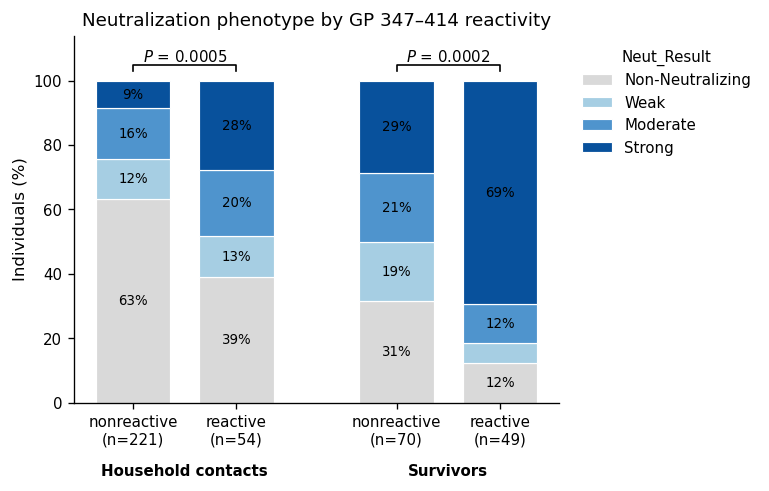

In [10]:
# Deliberately use a grayscale-friendly progression; change to journal palette if desired.
category_colors = {
    "Non-Neutralizing": "#D9D9D9",
    "Weak": "#A6CEE3",
    "Moderate": "#4F94CD",
    "Strong": "#08519C",
}

plot_rows=[]
for group in ["Household contact", "Survivor"]:
    for gp, gp_label in [(False,"GP-nonreactive"),(True,"GP-reactive")]:
        d=df[(df.Group==group) & (df.GP_reactive==gp)].dropna(subset=["Neut_Result"])
        counts=d["Neut_Result"].value_counts().reindex(ORDER, fill_value=0)
        for cat in ORDER:
            plot_rows.append({"Group":group,"GP_status":gp_label,"Category":cat,
                              "Count":counts[cat],"Percent":100*counts[cat]/counts.sum(),"N":counts.sum()})
plot_df=pd.DataFrame(plot_rows)

fig, ax = plt.subplots(figsize=(6.5,4.2))
labels=[]; x=[]; xpos=0
for group in ["Household contact","Survivor"]:
    for gp_label in ["GP-nonreactive","GP-reactive"]:
        sub=plot_df[(plot_df.Group==group)&(plot_df.GP_status==gp_label)]
        bottom=0
        for cat in ORDER:
            row=sub[sub.Category==cat].iloc[0]
            ax.bar(xpos,row.Percent,bottom=bottom,width=.72,color=category_colors[cat],
                   edgecolor="white",linewidth=.7,label=cat if xpos==0 else None)
            if row.Percent >= 8:
                ax.text(xpos,bottom+row.Percent/2,f"{row.Percent:.0f}%",ha="center",va="center",fontsize=8)
            bottom += row.Percent
        n=int(sub.N.iloc[0]); labels.append(f"{gp_label.replace('GP-','')}\n(n={n})"); x.append(xpos)
        xpos += 1
    xpos += .55
ax.set_xticks(x,labels)
ax.set_ylabel("Individuals (%)")
ax.set_ylim(0,100)
ax.set_title("Neutralization phenotype by GP 347–414 reactivity")
ax.text(.5,-.20,"Household contacts",transform=ax.get_xaxis_transform(),ha="center",fontweight="bold")
ax.text(3.05,-.20,"Survivors",transform=ax.get_xaxis_transform(),ha="center",fontweight="bold")
ax.legend(title="Neut_Result",bbox_to_anchor=(1.02,1),loc="upper left",frameon=False)

# --------------------------------------------------
# Statistical comparisons of full Neut_Result distribution
# --------------------------------------------------

def add_pvalue_bracket(ax, x1, x2, y, h, p):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y+h, y+h, y],
        color="black",
        lw=1,
        clip_on=False
    )

    if p < 0.0001:
        label = f"$P$ = {p:.1e}"
    elif p < 0.001:
        label = f"$P$ = {p:.4f}"
    else:
        label = f"$P$ = {p:.3f}"

    ax.text(
        (x1 + x2) / 2,
        y + h,
        label,
        ha="center",
        va="bottom",
        fontsize=9
    )


pvals_cat = {}

for group in ["Household contact", "Survivor"]:

    d = df[
        (df.Group == group) &
        df["Neut_Result"].notna()
    ]

    # Rows = GP status
    # Columns = neutralization categories
    table = pd.crosstab(
        d.GP_reactive,
        d["Neut_Result"]
    ).reindex(
        index=[False, True],
        columns=ORDER,
        fill_value=0
    )

    chi2, p, dof, expected = stats.chi2_contingency(table)

    pvals_cat[group] = p

    print(f"\n{group}")
    print(table)
    print(f"Chi-square = {chi2:.2f}")
    print(f"df = {dof}")
    print(f"p = {p:.3g}")

# Contact: bars 0 and 1
add_pvalue_bracket(
    ax,
    0, 1,
    y=103,
    h=2,
    p=pvals_cat["Household contact"]
)

# Survivor: bars 2.55 and 3.55
add_pvalue_bracket(
    ax,
    2.55, 3.55,
    y=103,
    h=2,
    p=pvals_cat["Survivor"]
)

# Make room above 100% for annotations
ax.set_ylim(0, 114)

fig.tight_layout()
"""for ext in ["png","pdf","svg"]:
    fig.savefig(FIG_DIR/f"figure1_neut_result_stacked.{ext}",bbox_inches="tight")"""
plt.show()

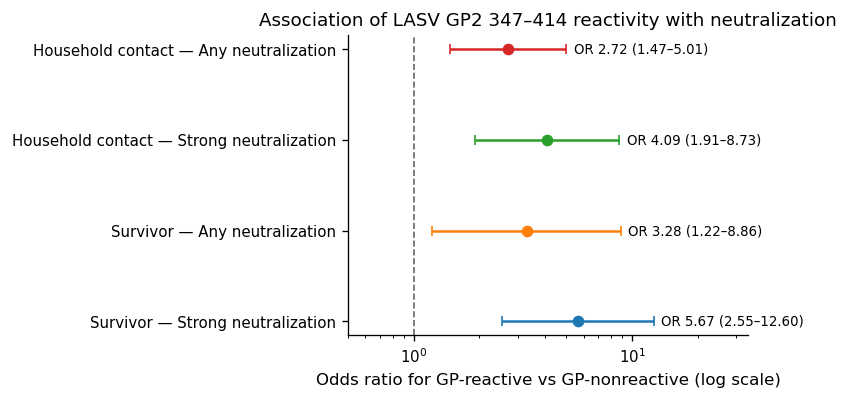

In [12]:
forest=results[results.Group.isin(["Household contact","Survivor"])].copy()
forest["Label"]=forest["Group"]+" — "+forest["Outcome"]
forest=forest.iloc[::-1].reset_index(drop=True)

y=np.arange(len(forest))
fig,ax=plt.subplots(figsize=(6.5,3.4))
for i,row in forest.iterrows():
    ax.errorbar(row.OR,i,xerr=[[row.OR-row.CI_low],[row.CI_high-row.OR]],fmt="o",capsize=3)
    ax.text(row.CI_high*1.08,i,f"OR {row.OR:.2f} ({row.CI_low:.2f}–{row.CI_high:.2f})",va="center",fontsize=8)
ax.axvline(1,ls="--",lw=1,color="0.4")
ax.set_xscale("log")
ax.set_yticks(y,forest.Label)
ax.set_xlabel("Odds ratio for GP-reactive vs GP-nonreactive (log scale)")
ax.set_title("Association of LASV GP2 347–414 reactivity with neutralization")
right=max(forest.CI_high)*2.7
ax.set_xlim(0.5,right)
fig.tight_layout()
"""for ext in ["png","pdf","svg"]:
    fig.savefig(FIG_DIR/f"figure3_effect_sizes_forest.{ext}",bbox_inches="tight")"""
plt.show()

### Goal: identify top 15 and bottom 15 for every GP2-reactivity / neutralization status 

In [13]:
ID = "individual"          # adjust to your ID column name
K = 15

d = df.dropna(subset=["Neut_Percent"])

out = []
for group, gp, label in groups:
    sub = d[(d.Group == group) & (d.GP_reactive == gp)]
    for end, sel in [("high", sub.nlargest(K, "Neut_Percent")),
                     ("low",  sub.nsmallest(K, "Neut_Percent"))]:
        s = sel[[ID, "Group", "GP_reactive", "Neut_Percent"]].copy()
        s["label"] = label.replace("\n", " ")
        s["end"] = end
        out.append(s)

picks = pd.concat(out, ignore_index=True)
picks.to_csv("neut_extremes_gp2_347_414.csv", index=False)

print(d.groupby(["Group", "GP_reactive"]).size())      # group sizes
print(picks.groupby(["label", "end"])["Neut_Percent"].agg(["size", "min", "max"]))

Group              GP_reactive
Household contact  False          221
                   True            54
Survivor           False           70
                   True            49
dtype: int64
                               size      min      max
label                    end                         
Contact GP2-nonreactive  high    15  83.3775  97.5217
                         low     15   0.0000   0.0000
Contact GP2-reactive     high    15  81.3821  88.4174
                         low     15   0.0000  20.0282
Survivor GP2-nonreactive high    15  83.8616  95.6953
                         low     15   0.0000  31.8809
Survivor GP2-reactive    high    15  90.3608  95.6349
                         low     15   7.5800  79.4109
